# Transformações Morfológicas em Imagens Digitais
### Teoria e Aplicação Prática com Python, NumPy e OpenCV

**Universidade Presbiteriana Mackenzie** · Faculdade de Computação e Informática · Ciência da Computação
**Disciplina:** Computação Visual · **Prof.:** André Kishimoto · **Projeto 2 (Proj2) – Opção 2: Tutorial teoria e prática**

**Integrantes do grupo**

| Nome completo | RA |
|---|---|
| Mateo Porcare | 10418276 |
| Enrico Minto Spanier | 10419775 |
| Guilherme Vecchi | 10418517 |
| Alexandre Luppi Severo e Silva | 10419724 |

---
## Sumário
1. Introdução
2. Preparação do ambiente
3. Teoria: elemento estruturante, erosão e dilatação
4. Prática 1: erosão e dilatação implementadas "na mão" (NumPy) vs. OpenCV
5. Teoria e prática: abertura e fechamento
6. Operadores extras: gradiente, top-hat e black-hat
7. Morfologia em tons de cinza
8. Aplicação: limpeza e segmentação de uma imagem de texto
9. Experimento interativo (widgets)
10. Exercícios propostos
11. Conclusões
12. Referências

## 1. Introdução

A **morfologia matemática** é um conjunto de técnicas de processamento de imagens baseado na **forma** (geometria) dos objetos. Em vez de olhar para a intensidade de um pixel isoladamente, ela compara a vizinhança do pixel com uma pequena forma de referência chamada **elemento estruturante** (*structuring element*, SE).

Aplicações típicas:

- remoção de ruídos isolados (ex.: ruído "sal e pimenta");
- preenchimento de pequenos furos e lacunas em objetos;
- separação de objetos que se tocam e junção de objetos próximos;
- extração de contornos e de estruturas (ex.: linhas de texto, células);
- pré-processamento para OCR, contagem de objetos e segmentação.

Neste tutorial, vamos primeiro entender a teoria dos operadores básicos (**erosão** e **dilatação**), implementá-los manualmente, comparar com o OpenCV e, em seguida, construir os operadores compostos (**abertura**, **fechamento**, **gradiente**, **top-hat** e **black-hat**), terminando com uma aplicação prática e um experimento interativo.

> **Observação:** todas as imagens usadas neste notebook são **geradas por código**, então ele roda sem precisar de arquivos externos (inclusive no Google Colab).

## 2. Preparação do ambiente

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
plt.rcParams["image.cmap"] = "gray"

print("OpenCV:", cv2.__version__)
print("NumPy :", np.__version__)

def mostrar(imagens, titulos, tam=(3.2, 3.2), cmap="gray"):
    # Mostra várias imagens lado a lado
    n = len(imagens)
    fig, eixos = plt.subplots(1, n, figsize=(tam[0] * n, tam[1]))
    eixos = np.atleast_1d(eixos)
    for ax, img, t in zip(eixos, imagens, titulos):
        ax.imshow(img, cmap=cmap, vmin=0, vmax=255, interpolation="nearest")
        ax.set_title(t, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

OpenCV: 4.13.0
NumPy : 2.4.4


## 3. Teoria

### 3.1 Elemento estruturante (SE)

O elemento estruturante é uma pequena matriz (normalmente binária) que define a **vizinhança** analisada em torno de cada pixel. Seu **tamanho** e sua **forma** determinam o efeito da operação. O OpenCV oferece três formas prontas em `cv2.getStructuringElement`:

- `cv2.MORPH_RECT`: retângulo (quadrado);
- `cv2.MORPH_ELLIPSE`: elipse (aproxima um círculo);
- `cv2.MORPH_CROSS`: cruz.

In [2]:
formas = {"RECT": cv2.MORPH_RECT, "ELLIPSE": cv2.MORPH_ELLIPSE, "CROSS": cv2.MORPH_CROSS}
for nome, f in formas.items():
    print(f"{nome} 5x5:")
    print(cv2.getStructuringElement(f, (5, 5)))
    print()

RECT 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

ELLIPSE 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]

CROSS 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]



### 3.2 Erosão e dilatação como filtros de ordenação (mínimo e máximo)

Seja $f$ a imagem, $B$ o elemento estruturante e $B_{(x,y)}$ a vizinhança definida por $B$ centrada no pixel $(x, y)$.

**Erosão** (filtro de **mínimo**):

$$ (f \ominus B)(x,y) = \min_{(s,t)\in B} f(x+s,\; y+t) $$

**Dilatação** (filtro de **máximo**):

$$ (f \oplus B)(x,y) = \max_{(s,t)\in B} f(x+s,\; y+t) $$

Em **imagens binárias** (objeto = 255, fundo = 0) isso vira uma interpretação geométrica simples:

| Operação | Efeito no objeto (branco) |
|---|---|
| **Erosão** | O pixel permanece branco **somente se o SE couber inteiro** dentro do objeto. O objeto **encolhe**; ruídos brancos pequenos desaparecem; furos aumentam. |
| **Dilatação** | O pixel vira branco se o SE **tocar** o objeto. O objeto **cresce**; furos pequenos se fecham; objetos próximos se unem. |

A erosão e a dilatação são **duais**: dilatar o objeto equivale a erodir o fundo (complemento) e vice-versa.

### 3.3 Operadores compostos

| Operador | Definição | Efeito principal |
|---|---|---|
| **Abertura** | $f \circ B = (f \ominus B) \oplus B$ | Remove objetos pequenos e "pontes" finas, mantendo o tamanho dos objetos grandes. |
| **Fechamento** | $f \bullet B = (f \oplus B) \ominus B$ | Fecha furos e lacunas pequenas dentro dos objetos. |
| **Gradiente** | $(f \oplus B) - (f \ominus B)$ | Realça o **contorno** dos objetos. |
| **Top-hat** | $f - (f \circ B)$ | Destaca objetos **claros** menores que o SE. |
| **Black-hat** | $(f \bullet B) - f$ | Destaca objetos **escuros** menores que o SE (furos, vales). |

Propriedade importante: abertura e fechamento são **idempotentes** (aplicar duas vezes seguidas dá o mesmo resultado que aplicar uma).

## 4. Prática 1: erosão e dilatação "na mão" vs. OpenCV

Primeiro, criamos uma imagem binária de teste com formas geométricas e adicionamos **ruído sal e pimenta** (pixels brancos e pretos aleatórios).

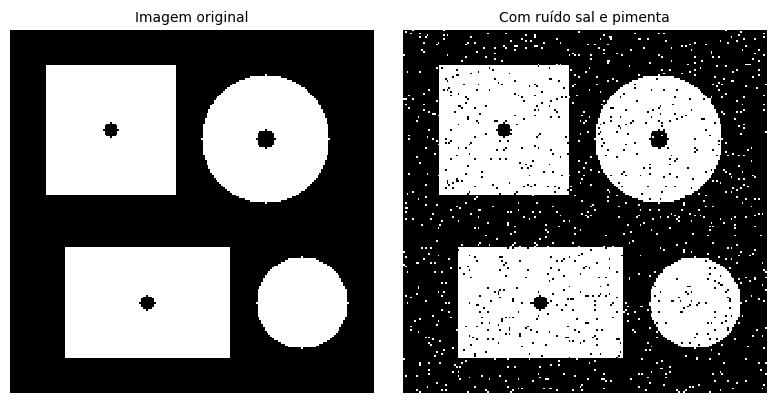

In [3]:
rng = np.random.default_rng(42)  # semente fixa -> resultados reproduzíveis

def criar_imagem_teste(tam=200):
    img = np.zeros((tam, tam), np.uint8)
    cv2.rectangle(img, (20, 20), (90, 90), 255, -1)          # quadrado
    cv2.circle(img, (140, 60), 35, 255, -1)                   # círculo
    cv2.rectangle(img, (30, 120), (120, 180), 255, -1)        # retângulo
    cv2.circle(img, (160, 150), 25, 255, -1)                  # círculo menor
    # furos internos (pretos) para testar o fechamento
    cv2.circle(img, (55, 55), 4, 0, -1)
    cv2.circle(img, (140, 60), 5, 0, -1)
    cv2.circle(img, (75, 150), 4, 0, -1)
    return img

def sal_e_pimenta(img, prob=0.03):
    ruido = img.copy()
    r = rng.random(img.shape)
    ruido[r < prob / 2] = 0          # pimenta
    ruido[r > 1 - prob / 2] = 255    # sal
    return ruido

limpa = criar_imagem_teste()
ruidosa = sal_e_pimenta(limpa, 0.06)
mostrar([limpa, ruidosa], ["Imagem original", "Com ruído sal e pimenta"], tam=(4, 4))

### 4.1 Implementação manual com NumPy

A ideia: para cada pixel, olhamos a vizinhança definida pelo SE e pegamos o **mínimo** (erosão) ou o **máximo** (dilatação) apenas entre os pixels em que o SE vale 1.

Para a borda da imagem, usamos *padding*: **255 na erosão** e **0 na dilatação**, o que equivale ao comportamento padrão do OpenCV (a borda não interfere no resultado).

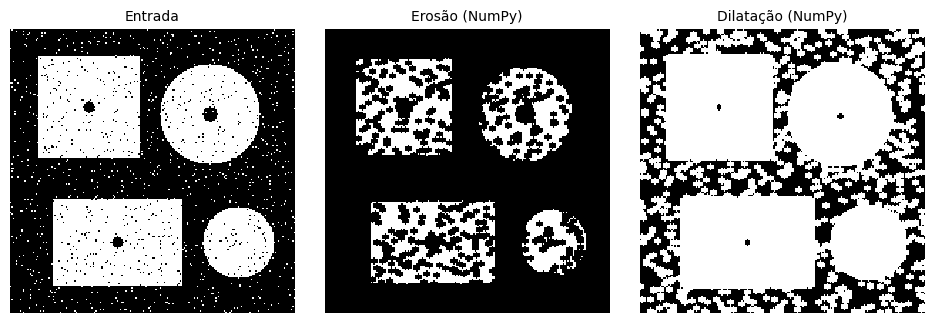

In [4]:
def erosao_manual(img, se):
    h, w = img.shape
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    # padding "neutro" para o mínimo: 255 (não altera o resultado)
    pad = np.pad(img, ((ph, ph), (pw, pw)), constant_values=255)
    saida = np.empty_like(img)
    for y in range(h):
        for x in range(w):
            janela = pad[y:y + kh, x:x + kw]
            saida[y, x] = janela[se == 1].min()
    return saida

def dilatacao_manual(img, se):
    h, w = img.shape
    kh, kw = se.shape
    ph, pw = kh // 2, kw // 2
    # padding "neutro" para o máximo: 0
    pad = np.pad(img, ((ph, ph), (pw, pw)), constant_values=0)
    saida = np.empty_like(img)
    for y in range(h):
        for x in range(w):
            janela = pad[y:y + kh, x:x + kw]
            saida[y, x] = janela[se == 1].max()
    return saida

se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

ero_m = erosao_manual(ruidosa, se)
dil_m = dilatacao_manual(ruidosa, se)
ero_cv = cv2.erode(ruidosa, se)
dil_cv = cv2.dilate(ruidosa, se)

mostrar([ruidosa, ero_m, dil_m], ["Entrada", "Erosão (NumPy)", "Dilatação (NumPy)"])

### 4.2 Conferindo se a nossa implementação bate com a do OpenCV

Erosão    idêntica ao OpenCV? True
Dilatação idêntica ao OpenCV? True


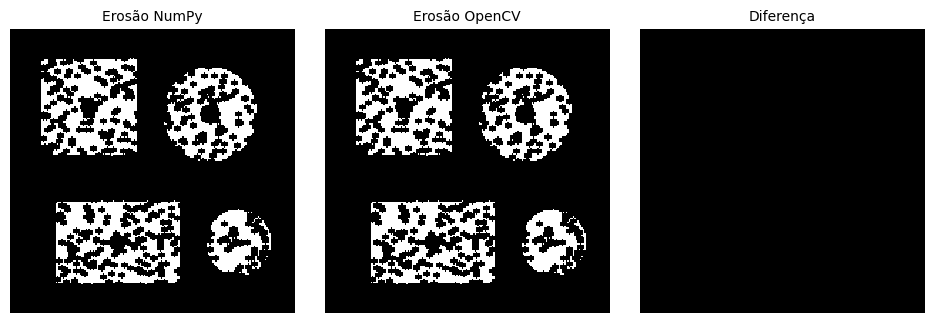

In [5]:
print("Erosão    idêntica ao OpenCV?", np.array_equal(ero_m, ero_cv))
print("Dilatação idêntica ao OpenCV?", np.array_equal(dil_m, dil_cv))

mostrar([ero_m, ero_cv, cv2.absdiff(ero_m, ero_cv)],
        ["Erosão NumPy", "Erosão OpenCV", "Diferença"])

**Análise.** Repare que:

- a **erosão** eliminou os pontos brancos isolados (sal), mas **aumentou** os pontos pretos (pimenta) e os furos dentro dos objetos;
- a **dilatação** fez o contrário: eliminou a pimenta e os furos pequenos, mas **engordou** os pontos brancos e os objetos.

Nenhuma das duas sozinha resolve o problema — por isso combinamos as operações na próxima seção.

**Desempenho:** laços em Python puro são lentos. Vamos medir a diferença.

In [6]:
import time

t0 = time.perf_counter(); erosao_manual(ruidosa, se);  t_man = time.perf_counter() - t0
t0 = time.perf_counter(); cv2.erode(ruidosa, se);      t_cv  = time.perf_counter() - t0

print(f"NumPy (laços) : {t_man * 1000:8.2f} ms")
print(f"OpenCV        : {t_cv * 1000:8.2f} ms")
print(f"OpenCV é ~{t_man / max(t_cv, 1e-9):.0f}x mais rápido")

NumPy (laços) :    84.45 ms
OpenCV        :     0.14 ms
OpenCV é ~593x mais rápido


## 5. Abertura e fechamento

- **Abertura** = erosão seguida de dilatação → remove o ruído **branco** (sal).
- **Fechamento** = dilatação seguida de erosão → remove o ruído **preto** (pimenta) e fecha furos.

Para limpar os dois tipos de ruído, aplicamos **abertura + fechamento**.

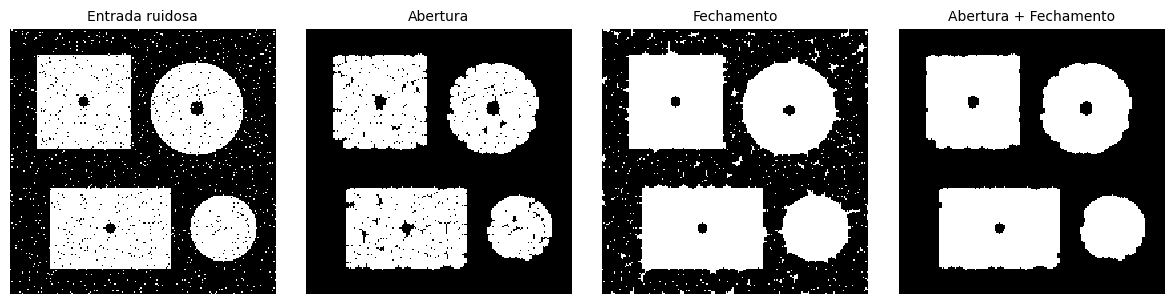

In [7]:
se5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

abertura   = cv2.morphologyEx(ruidosa, cv2.MORPH_OPEN,  se5)
fechamento = cv2.morphologyEx(ruidosa, cv2.MORPH_CLOSE, se5)
ab_fe      = cv2.morphologyEx(abertura, cv2.MORPH_CLOSE, se5)

mostrar([ruidosa, abertura, fechamento, ab_fe],
        ["Entrada ruidosa", "Abertura", "Fechamento", "Abertura + Fechamento"], tam=(3, 3))

Podemos verificar de forma objetiva o quanto a limpeza se aproximou da imagem original, contando os pixels diferentes:

In [8]:
def erro(a, b):
    return int(np.count_nonzero(a != b))

print("Pixels errados em relação à imagem limpa:")
print(f"  Entrada ruidosa       : {erro(ruidosa, limpa)}")
print(f"  Abertura              : {erro(abertura, limpa)}")
print(f"  Fechamento            : {erro(fechamento, limpa)}")
print(f"  Abertura + Fechamento : {erro(ab_fe, limpa)}")

# Idempotência: aplicar a abertura duas vezes dá o mesmo resultado
abertura2 = cv2.morphologyEx(abertura, cv2.MORPH_OPEN, se5)
print("\nAbertura é idempotente?", np.array_equal(abertura, abertura2))

Pixels errados em relação à imagem limpa:
  Entrada ruidosa       : 1209
  Abertura              : 1234
  Fechamento            : 1484
  Abertura + Fechamento : 540

Abertura é idempotente? True


### 5.1 Efeito do tamanho do elemento estruturante

SE pequeno remove pouco ruído; SE grande remove mais ruído, mas **deforma** os objetos (cantos arredondados, objetos pequenos somem).

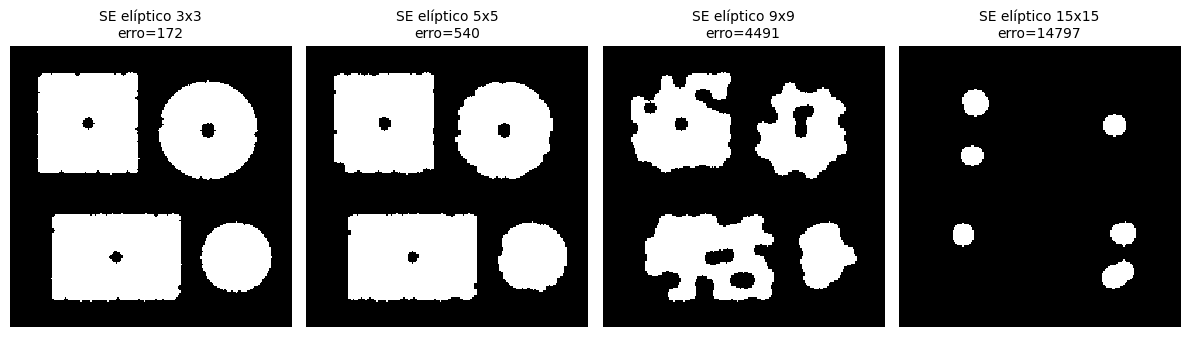

In [9]:
tamanhos = [3, 5, 9, 15]
resultados = []
for k in tamanhos:
    s = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    r = cv2.morphologyEx(cv2.morphologyEx(ruidosa, cv2.MORPH_OPEN, s), cv2.MORPH_CLOSE, s)
    resultados.append(r)

mostrar(resultados, [f"SE elíptico {k}x{k}\nerro={erro(r, limpa)}" for k, r in zip(tamanhos, resultados)],
        tam=(3, 3.3))

### 5.2 Efeito da forma do elemento estruturante

A forma do SE "imprime" sua geometria nos objetos: o retângulo preserva cantos retos, a elipse arredonda, e a cruz deixa cantos "chanfrados".

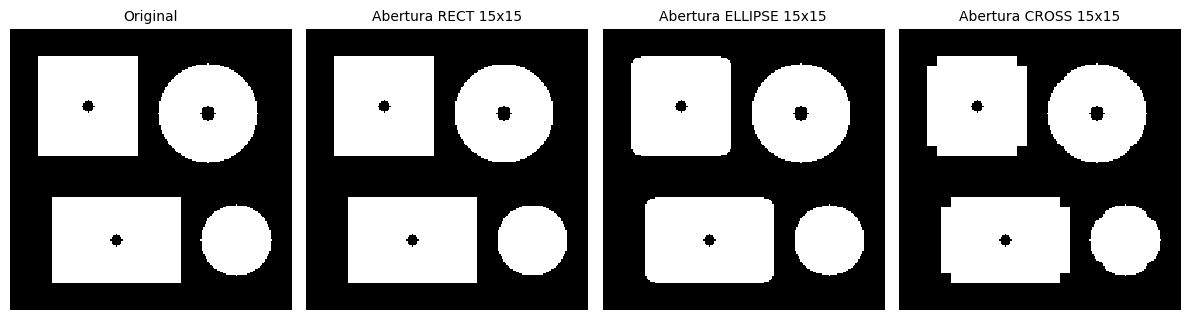

In [10]:
k = 15
resultados, nomes = [], []
for nome, f in formas.items():
    s = cv2.getStructuringElement(f, (k, k))
    resultados.append(cv2.morphologyEx(limpa, cv2.MORPH_OPEN, s))
    nomes.append(f"Abertura {nome} {k}x{k}")

mostrar([limpa] + resultados, ["Original"] + nomes, tam=(3, 3.3))

## 6. Operadores extras: gradiente, top-hat e black-hat

Todos usam `cv2.morphologyEx`:

- `cv2.MORPH_GRADIENT`: dilatação − erosão → **contorno**;
- `cv2.MORPH_TOPHAT`: imagem − abertura → **detalhes claros** pequenos;
- `cv2.MORPH_BLACKHAT`: fechamento − imagem → **detalhes escuros** pequenos (furos).

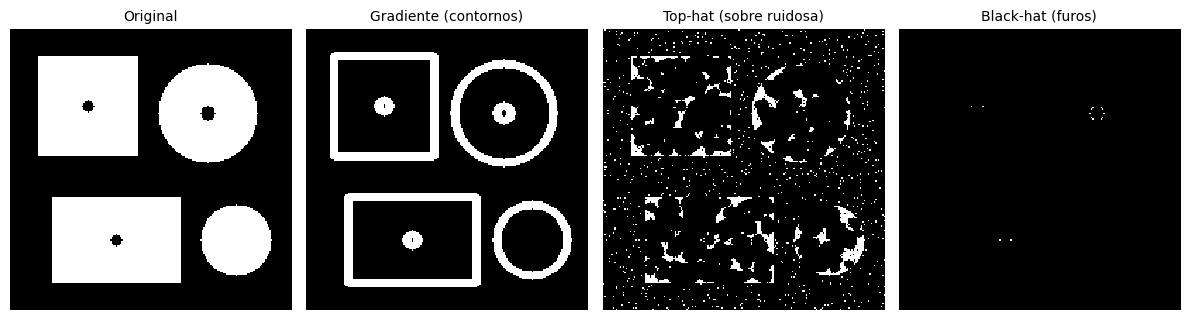

In [11]:
s = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

gradiente = cv2.morphologyEx(limpa, cv2.MORPH_GRADIENT, s)
tophat    = cv2.morphologyEx(ruidosa, cv2.MORPH_TOPHAT, s)
blackhat  = cv2.morphologyEx(limpa, cv2.MORPH_BLACKHAT, s)

mostrar([limpa, gradiente, tophat, blackhat],
        ["Original", "Gradiente (contornos)", "Top-hat (sobre ruidosa)", "Black-hat (furos)"], tam=(3, 3.3))

Observe que o **black-hat** destacou exatamente os furos que colocamos dentro das formas, e o **top-hat** isolou os pontos brancos de ruído (que são menores que o SE).

## 7. Morfologia em tons de cinza

Como a erosão e a dilatação são mínimo e máximo, elas funcionam diretamente em imagens em **tons de cinza**:

- a **erosão** escurece a imagem e remove detalhes claros pequenos;
- a **dilatação** clareia a imagem e remove detalhes escuros pequenos.

Um uso clássico do **top-hat** em cinza é **corrigir iluminação irregular**, como mostrado a seguir.

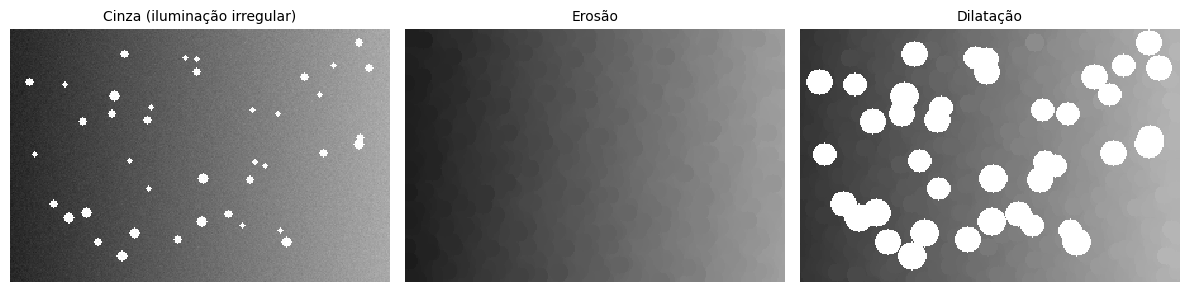

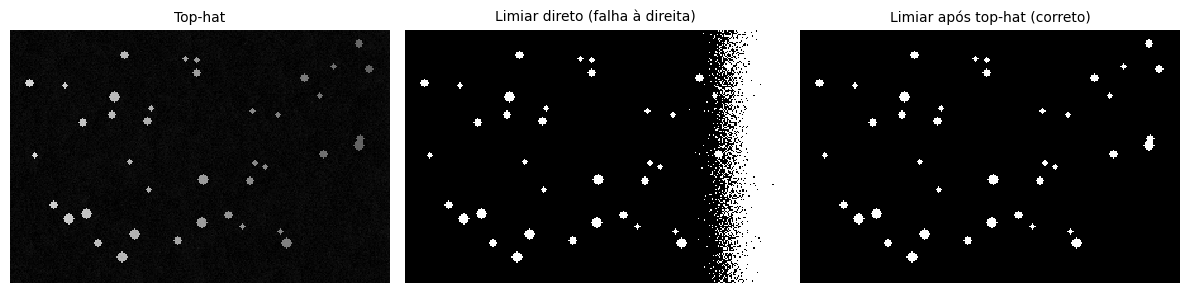

In [12]:
# Imagem em cinza: pequenos "grãos" claros sobre fundo com gradiente de iluminação
h, w = 200, 300
fundo = np.tile(np.linspace(40, 170, w), (h, 1)).astype(np.float32)
img_cinza = fundo.copy()
for _ in range(40):
    cx, cy = int(rng.integers(10, w - 10)), int(rng.integers(10, h - 10))
    cv2.circle(img_cinza, (cx, cy), int(rng.integers(2, 5)), 255, -1)
img_cinza = np.clip(img_cinza + rng.normal(0, 4, img_cinza.shape), 0, 255).astype(np.uint8)

s_grande = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
ero_g = cv2.erode(img_cinza, s_grande)
dil_g = cv2.dilate(img_cinza, s_grande)
th_g  = cv2.morphologyEx(img_cinza, cv2.MORPH_TOPHAT, s_grande)
_, bin_direta = cv2.threshold(img_cinza, 150, 255, cv2.THRESH_BINARY)
_, bin_tophat = cv2.threshold(th_g, 60, 255, cv2.THRESH_BINARY)

mostrar([img_cinza, ero_g, dil_g], ["Cinza (iluminação irregular)", "Erosão", "Dilatação"], tam=(4, 3))
mostrar([th_g, bin_direta, bin_tophat],
        ["Top-hat", "Limiar direto (falha à direita)", "Limiar após top-hat (correto)"], tam=(4, 3))

O limiar global aplicado direto na imagem **falha** porque o fundo à direita é mais claro. Depois do top-hat, o fundo "plano" é removido e o mesmo tipo de limiar **segmenta os grãos corretamente**.

## 8. Aplicação: limpeza e segmentação de uma imagem de texto

Cenário: um documento escaneado com ruído. Queremos (a) limpar o ruído e (b) detectar as **palavras/linhas** como regiões — passo comum em pipelines de OCR.

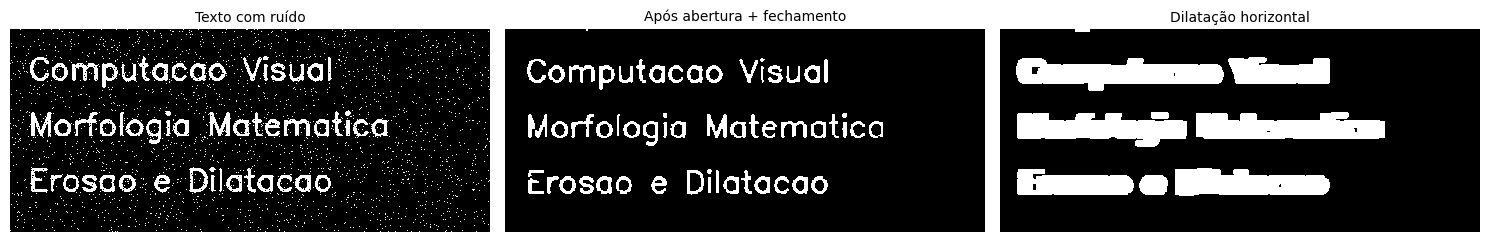

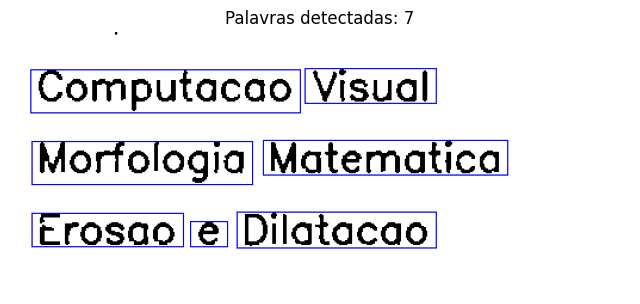

In [13]:
# Gera uma "página" com texto
pagina = np.full((220, 520), 255, np.uint8)
linhas = ["Computacao Visual", "Morfologia Matematica", "Erosao e Dilatacao"]
for i, t in enumerate(linhas):
    cv2.putText(pagina, t, (20, 55 + i * 60), cv2.FONT_HERSHEY_SIMPLEX, 1.1, 0, 2, cv2.LINE_AA)

# Texto branco sobre fundo preto (objeto = 255) e ruído
_, texto = cv2.threshold(pagina, 127, 255, cv2.THRESH_BINARY_INV)
texto_ruidoso = sal_e_pimenta(texto, 0.05)

# 1) Limpeza: abertura (remove sal) + fechamento (remove pimenta, fecha pequenas falhas)
s_peq = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
limpo = cv2.morphologyEx(texto_ruidoso, cv2.MORPH_OPEN, s_peq)
limpo = cv2.morphologyEx(limpo, cv2.MORPH_CLOSE, s_peq)

# 2) Segmentação de palavras: dilatação horizontal "borra" letras de uma mesma palavra
s_palavra = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 3))
blocos = cv2.dilate(limpo, s_palavra)

# 3) Contornos dos blocos -> caixas delimitadoras
contornos, _ = cv2.findContours(blocos, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
caixas = [cv2.boundingRect(c) for c in contornos if cv2.contourArea(c) > 150]

resultado = cv2.cvtColor(255 - limpo, cv2.COLOR_GRAY2BGR)
for (x, y, bw, bh) in caixas:
    cv2.rectangle(resultado, (x, y), (x + bw, y + bh), (255, 0, 0), 1)

mostrar([texto_ruidoso, limpo, blocos], ["Texto com ruído", "Após abertura + fechamento", "Dilatação horizontal"], tam=(5, 2.6))
plt.figure(figsize=(8, 3.5)); plt.imshow(resultado[:, :, ::-1]); plt.axis("off")
plt.title(f"Palavras detectadas: {len(caixas)}"); plt.show()

**Pipeline resumido:** ruído → abertura/fechamento (limpeza) → dilatação com SE retangular largo (une letras em palavras) → contornos → caixas delimitadoras.

## 9. Experimento interativo

Use os controles abaixo para variar a **operação**, a **forma** e o **tamanho** do elemento estruturante e o **nível de ruído**, e observe o efeito em tempo real.

> Requer `ipywidgets`. Funciona no Jupyter local e no Google Colab. Se os controles não aparecerem, execute `!pip install ipywidgets` e reinicie o kernel.

In [14]:
import ipywidgets as widgets
from IPython.display import display

OPERACOES = {
    "Erosão": cv2.MORPH_ERODE,
    "Dilatação": cv2.MORPH_DILATE,
    "Abertura": cv2.MORPH_OPEN,
    "Fechamento": cv2.MORPH_CLOSE,
    "Gradiente": cv2.MORPH_GRADIENT,
    "Top-hat": cv2.MORPH_TOPHAT,
    "Black-hat": cv2.MORPH_BLACKHAT,
}

def experimento(operacao, forma, tamanho, ruido, iteracoes):
    global rng
    rng = np.random.default_rng(1)  # mesmo ruído a cada ajuste, só a prob. muda
    entrada = sal_e_pimenta(limpa, ruido)
    se_i = cv2.getStructuringElement(formas[forma], (tamanho, tamanho))
    saida = cv2.morphologyEx(entrada, OPERACOES[operacao], se_i, iterations=iteracoes)
    mostrar([entrada, se_i * 255, saida],
            ["Entrada", f"SE {forma} {tamanho}x{tamanho}", f"{operacao} (x{iteracoes})"], tam=(3.5, 3.5))

try:
    widgets.interact(
        experimento,
        operacao=widgets.Dropdown(options=list(OPERACOES), value="Abertura", description="Operação"),
        forma=widgets.Dropdown(options=list(formas), value="ELLIPSE", description="Forma do SE"),
        tamanho=widgets.IntSlider(value=5, min=1, max=31, step=2, description="Tamanho"),
        ruido=widgets.FloatSlider(value=0.05, min=0.0, max=0.2, step=0.01, description="Ruído"),
        iteracoes=widgets.IntSlider(value=1, min=1, max=5, description="Iterações"),
    )
except Exception as e:
    print("Widgets indisponíveis neste ambiente:", e)
    experimento("Abertura", "ELLIPSE", 5, 0.05, 1)

interactive(children=(Dropdown(description='Operação', index=2, options=('Erosão', 'Dilatação', 'Abertura', 'F…

## 10. Exercícios propostos

1. Aumente o ruído para 15% e encontre o menor SE que mantém o número de pixels errados abaixo de 600.
2. Por que a abertura com SE 15x15 *retangular* preserva os cantos do quadrado, mas a *elíptica* não?
3. Implemente manualmente o **gradiente morfológico** usando apenas `erosao_manual` e `dilatacao_manual` e compare com `cv2.MORPH_GRADIENT`.
4. Na Seção 8, o que acontece se o SE horizontal for `(40, 3)`? E `(15, 15)`? Explique.
5. Aplique top-hat e black-hat em uma foto real em tons de cinza (ex.: `cv2.imread("foto.jpg", 0)`) e interprete o resultado.

## 11. Conclusões

- Erosão e dilatação são **filtros de mínimo e máximo** sobre uma vizinhança definida pelo elemento estruturante; sua implementação manual coincide exatamente com a do OpenCV, que é muito mais rápida.
- **Abertura** remove ruído claro e objetos pequenos; **fechamento** remove ruído escuro e fecha furos; combiná-las limpa ruído sal e pimenta sem alterar muito o tamanho dos objetos.
- O **tamanho** do SE controla *quanto* é removido (e quanto se deforma); a **forma** controla *como* a geometria dos objetos é modificada.
- **Gradiente, top-hat e black-hat** extraem contornos, grãos claros e furos, e o top-hat ajuda a corrigir iluminação irregular antes da limiarização.
- Em pipelines reais (como a detecção de palavras da Seção 8), a morfologia costuma ser uma etapa de **pré/pós-processamento** combinada com limiarização e detecção de contornos.

## 12. Referências

1. GONZALEZ, R. C.; WOODS, R. E. **Digital Image Processing**. 4. ed. Pearson, 2018. (Cap. 9 – Morphological Image Processing.)
2. SERRA, J. **Image Analysis and Mathematical Morphology**. Academic Press, 1982.
3. SOILLE, P. **Morphological Image Analysis: Principles and Applications**. 2. ed. Springer, 2004.
4. OpenCV. **Morphological Transformations** (tutorial oficial). Disponível em: https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html
5. OpenCV. **Image Filtering – `erode`, `dilate`, `morphologyEx`, `getStructuringElement`**. Disponível em: https://docs.opencv.org/4.x/d4/d86/group__imgproc__filter.html
6. HARRIS, C. R. et al. **Array programming with NumPy**. *Nature*, v. 585, p. 357–362, 2020.
7. HUNTER, J. D. **Matplotlib: A 2D graphics environment**. *Computing in Science & Engineering*, v. 9, n. 3, p. 90–95, 2007.

---
*Projeto 2 – Computação Visual – Universidade Presbiteriana Mackenzie.*